# 04 · XGBoost, LightGBM and regularization
Explore sequential boosting and validate whether L1/L2 penalties, leaf constraints and smaller depth reduce overfitting.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_data, feature_frame
active=ROOT/'data'/'active_dataset.csv'
if not active.exists():
    raise FileNotFoundError('Run python -m src.train first, then restart the notebook kernel.')
df=load_data(active)
print('Rows, columns:',df.shape)


Rows, columns: (395, 33)


In [2]:
metrics=pd.read_csv(ROOT/'results'/'model_metrics.csv')
boost=pd.read_csv(ROOT/'results'/'boosting_regularization.csv')
print('Training mode and dataset provenance are described in models/manifest.json')
import json
manifest=json.loads((ROOT/'models'/'manifest.json').read_text())
display(manifest['source'])
summary=metrics[(metrics.scenario=='early')&(metrics.task=='grade')]
display(summary[['model','train_rmse','test_rmse','test_mae','test_r2','cv_score','train_seconds']])

Training mode and dataset provenance are described in models/manifest.json


{'status': 'VERIFIED REAL UCI DATA',
 'verified': True,
 'synthetic': False,
 'subject': 'mat (Mathematics)',
 'sha256': 'e47f9ee225e1ee6e69b7564e6dac7123e80b8486677fe111f351964cef5dec80',
 'sha256_short': 'e47f9ee225e1',
 'path': '/Users/yashkhadgi/Downloads/student_performance_ensemble_project/data/raw/student-mat.csv',
 'name': 'student-mat.csv',
 'description': 'Official UCI Student Performance Mathematics dataset, verified by exact SHA-256 cryptographic match.',
 'uci_url': 'https://archive.ics.uci.edu/dataset/320/student+performance',
 'citation': 'Cortez, P. (2008). Student Performance. UCI Machine Learning Repository. https://doi.org/10.24432/C5TG7T'}

,model,train_rmse,test_rmse,test_mae,test_r2,cv_score,train_seconds
0,Decision Tree,3.94621,3.97026,2.92373,0.25538,-4.07326,0.160
1,Bagging,2.33325,3.95643,2.89967,0.26056,-3.90249,0.985
2,Random Forest,2.10373,3.97179,2.91516,0.25480,-3.89544,1.235
3,XGBoost,3.36372,3.92885,3.06286,0.27083,-4.03877,0.462
4,LightGBM,3.04337,3.91925,3.09186,0.27439,-4.02390,0.234


,model,configuration,train_rmse,validation_rmse
0,XGBoost,Less constrained,0.001482,4.299420
1,XGBoost,L1 Regularized (reg_alpha=4.0),1.383691,4.453124
2,XGBoost,L2 Regularized (reg_lambda=10.0),1.745675,4.446008
3,XGBoost,Conservative Regularized,2.795841,4.473530
4,LightGBM,Less constrained,0.044754,4.476431
5,LightGBM,L1 Regularized (reg_alpha=4.0),2.027974,4.454364
6,LightGBM,L2 Regularized (reg_lambda=10.0),2.208735,4.423638
7,LightGBM,Conservative Regularized,2.956457,4.515590


/var/folders/xs/fkmh2t1x4f75c59yd6qzmvr00000gn/T/ipykernel_17005/1661154513.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x['label']=x['model']+' / '+x['configuration']


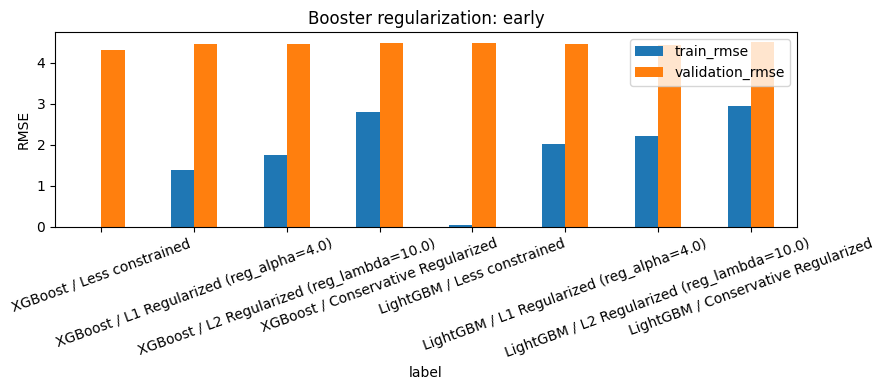

,model,configuration,train_rmse,validation_rmse
8,XGBoost,Less constrained,0.001013,1.448199
9,XGBoost,L1 Regularized (reg_alpha=4.0),0.700067,1.484607
10,XGBoost,L2 Regularized (reg_lambda=10.0),0.853639,1.772674
11,XGBoost,Conservative Regularized,1.411094,1.903630
12,LightGBM,Less constrained,0.012058,1.338414
13,LightGBM,L1 Regularized (reg_alpha=4.0),1.024724,1.448378
14,LightGBM,L2 Regularized (reg_lambda=10.0),1.094752,1.528919
15,LightGBM,Conservative Regularized,1.416613,1.548100


/var/folders/xs/fkmh2t1x4f75c59yd6qzmvr00000gn/T/ipykernel_17005/1661154513.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x['label']=x['model']+' / '+x['configuration']


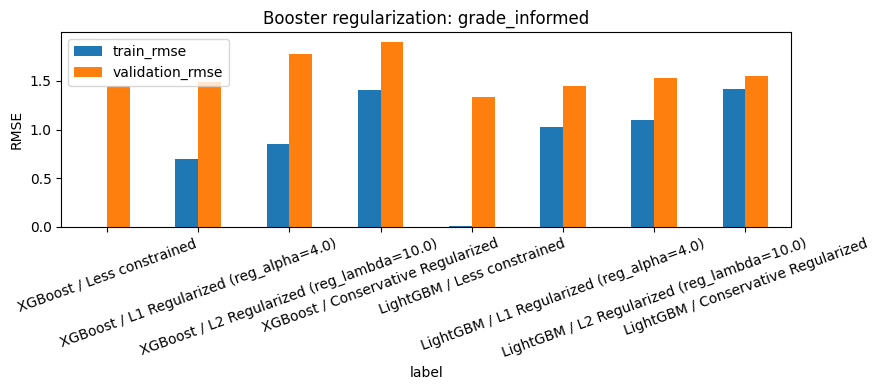

In [3]:
for scenario in ['early','grade_informed']:
    x=boost[boost.scenario==scenario]
    display(x[['model','configuration','train_rmse','validation_rmse']])
    fig,ax=plt.subplots(figsize=(9,4))
    x['label']=x['model']+' / '+x['configuration']
    x.set_index('label')[['train_rmse','validation_rmse']].plot.bar(ax=ax,rot=20)
    ax.set(title=f'Booster regularization: {scenario}',ylabel='RMSE');plt.tight_layout();plt.show()

**Reflect:** Fewer leaves, smaller trees, shrinkage, regularization and row/column subsampling affect model complexity. Regularization improves **generalization** only when validation performance confirms it. Compare the CV scores to choose models. The test set is for final reporting, not tuning.

In [4]:
from sklearn.metrics import confusion_matrix
pred=pd.read_csv(ROOT/'results'/'test_predictions.csv')
x=pred[(pred.scenario=='early')&(pred.task=='risk')&(pred.model=='XGBoost')]
cm=confusion_matrix(x.actual.astype(int),x.predicted.astype(int),labels=[0,1])
print('XGBoost risk confusion matrix [labels 0 = no risk, 1 = risk]:\n',cm)

XGBoost risk confusion matrix [labels 0 = no risk, 1 = risk]:
 [[48  5]
 [14 12]]
